In [1]:
#load libraries
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
import statsmodels.stats.api as sms
from statsmodels.compat import lzip
import matplotlib.pyplot as plt
import numpy as np

In [5]:
#Assumption 1
#Calculating Descriptive Statistics
df = pd.read_csv('PubsDeaths.csv') #load in the data
pd.options.display.float_format = '{:.0f}'.format #set the decimals (0f = 0 decimals)
df.describe() #describe the data

,Pubs,Deaths,name
count,8,8,8
mean,111,4773,4
std,160,2899,2
min,10,1044,1
25%,36,2735,3
50%,62,4540,4
75%,89,6303,6
max,500,10000,8


In [6]:
#Assumption 1
#Remove extreme values
df = df[df['Pubs'] < 500]
df.describe()

,Pubs,Deaths,name
count,7,7,7
mean,55,4026,4
std,32,2145,2
min,10,1044,1
25%,32,2519,2
50%,55,3992,4
75%,78,5592,6
max,100,6923,7


<Axes: xlabel='ppgdp', ylabel='infantMortality'>

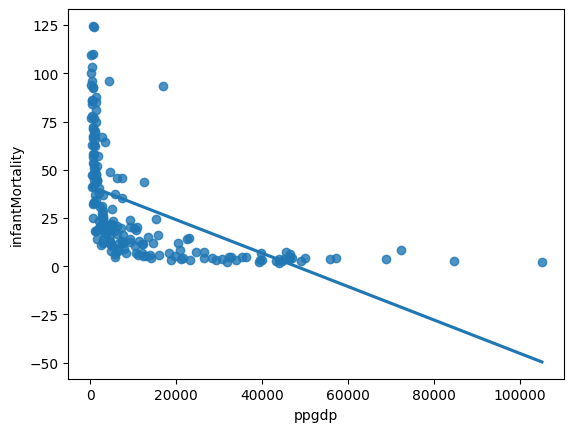

In [13]:
#Assumption 3
#Logarithmic relationship
UN = sm.datasets.get_rdataset('UN','carData').data
UN = UN.dropna()
infantMortality = UN['infantMortality']
ppgdp = UN['ppgdp']

sns.regplot(x = ppgdp,y = infantMortality,ci=None)

<Axes: xlabel='ppgdp', ylabel='infantMortality'>

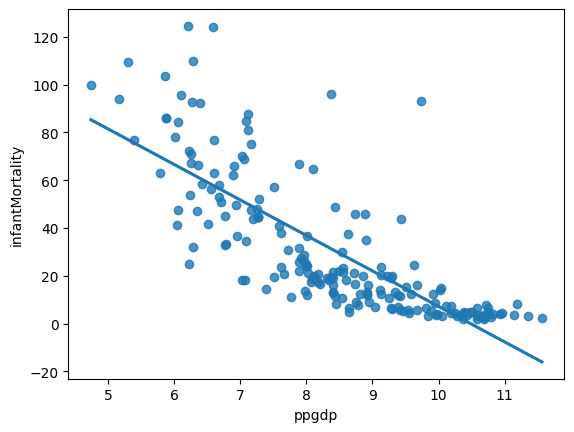

In [14]:
#Assumption 3
#Logarithmic transformation
import numpy as np
logppgdp = np.log(ppgdp)
sns.regplot(x = logppgdp,y = infantMortality,ci=None)

In [16]:
#regression with logppgdp
UN['logppgdp'] = np.log(UN['ppgdp'])

y = UN['infantMortality']
X = UN['logppgdp']
X = sm.add_constant(X)
modellog = sm.OLS(y,X).fit()
print(modellog.summary())

                            OLS Regression Results                            
Dep. Variable:        infantMortality   R-squared:                       0.617
Model:                            OLS   Adj. R-squared:                  0.615
Method:                 Least Squares   F-statistic:                     308.0
Date:                Wed, 08 Jul 2026   Prob (F-statistic):           1.09e-41
Time:                        14:03:04   Log-Likelihood:                -832.19
No. Observations:                 193   AIC:                             1668.
Df Residuals:                     191   BIC:                             1675.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        155.7698      7.243     21.506      0.0

Text(0.5, 1.0, 'Total Number of Cases in the Netherlands March 2020')

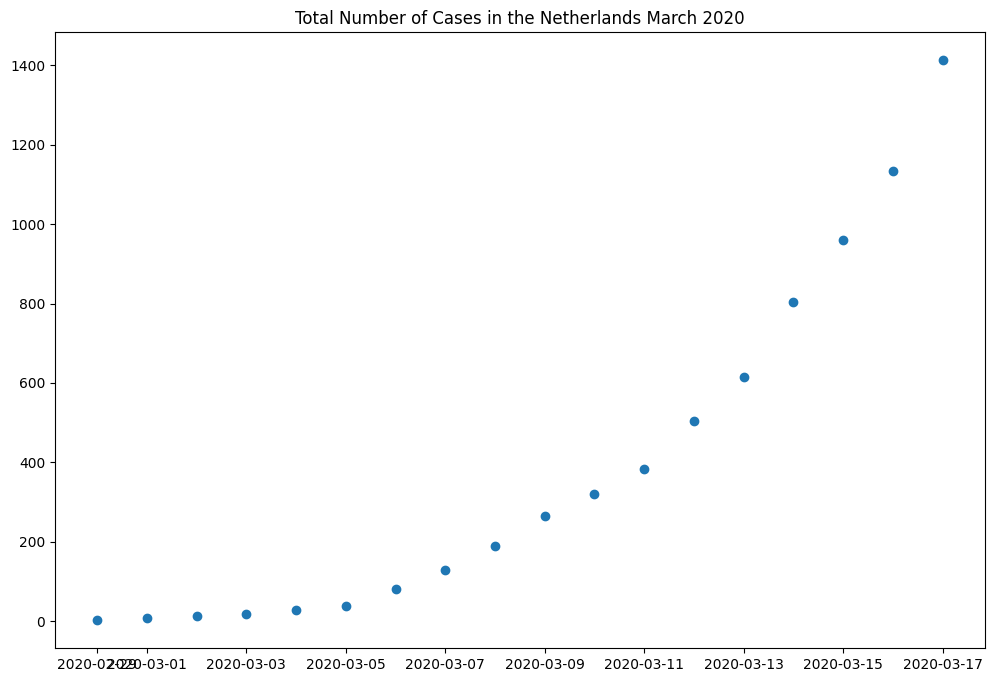

In [17]:
#Assumption 3
#Exponential regression
import matplotlib.pyplot as plt
NL_Covid = pd.read_excel('NL_Covid_Data.xlsx')
plt.figure(figsize=(12,8))
plt.scatter(x = NL_Covid.Date, y = NL_Covid.Total_Cases)
plt.title('Total Number of Cases in the Netherlands March 2020')


<Axes: xlabel='Age', ylabel='Salary'>

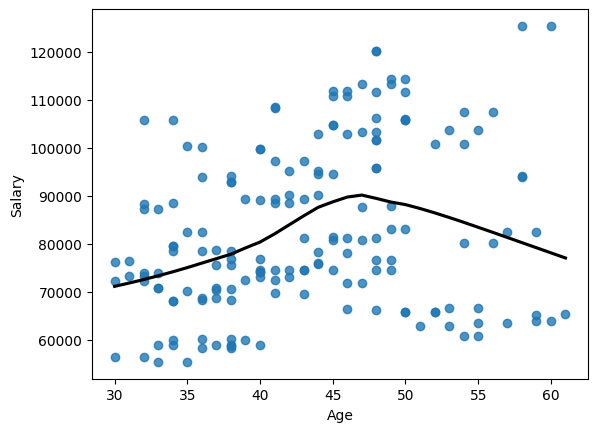

In [19]:
#Assumption 3
#Create scatterplot with lowess curve
Uni_salaries = pd.read_excel('University Salaries.xlsx')
sns.regplot(x = Uni_salaries.Age, y = Uni_salaries.Salary, lowess = True,line_kws={"color": "black"})

In [21]:
#Polynomial Regression
Uni_salaries['Age2'] = pow(Uni_salaries['Age'],2) #create squared age variable

y = Uni_salaries['Salary']
X = Uni_salaries[['Age','Age2']]
X = sm.add_constant(X)

modelpoly = sm.OLS(y,X).fit() #regression model with polynomial variable

print(modelpoly.summary())


                            OLS Regression Results                            
Dep. Variable:                 Salary   R-squared:                       0.126
Model:                            OLS   Adj. R-squared:                  0.115
Method:                 Least Squares   F-statistic:                     12.01
Date:                Wed, 08 Jul 2026   Prob (F-statistic):           1.34e-05
Time:                        14:13:07   Log-Likelihood:                -1887.5
No. Observations:                 170   AIC:                             3781.
Df Residuals:                     167   BIC:                             3791.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const      -5.992e+04   3.78e+04     -1.586      0.1

In [22]:
#Regression with only Age
X = Uni_salaries['Age']
X = sm.add_constant(X)

modellinear = sm.OLS(y,X2).fit() #regression model with no transformations

print(modellinear.summary())

                            OLS Regression Results                            
Dep. Variable:                 Salary   R-squared:                       0.126
Model:                            OLS   Adj. R-squared:                  0.115
Method:                 Least Squares   F-statistic:                     12.01
Date:                Wed, 08 Jul 2026   Prob (F-statistic):           1.34e-05
Time:                        14:13:11   Log-Likelihood:                -1887.5
No. Observations:                 170   AIC:                             3781.
Df Residuals:                     167   BIC:                             3791.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const      -5.992e+04   3.78e+04     -1.586      0.1

In [9]:
#Assumption 3
#Exponential Regression
#Note that you cannot exponentiate a date, so you have to create a new variable ranging from 1 to 18
NL_Covid = NL_Covid.assign(Time = range(1,19)) #note that 19 is not included in the variable
NL_Covid = NL_Covid.assign(Time2 = pow(NL_Covid.Time,2)) 
modelexp = sm.formula.ols('Total_Cases~Time + Time2',data=NL_Covid).fit()
print(modelexp.summary())

                            OLS Regression Results                            
Dep. Variable:            Total_Cases   R-squared:                       0.993
Model:                            OLS   Adj. R-squared:                  0.992
Method:                 Least Squares   F-statistic:                     1048.
Date:                Tue, 13 Jan 2026   Prob (F-statistic):           7.73e-17
Time:                        16:14:21   Log-Likelihood:                -89.863
No. Observations:                  18   AIC:                             185.7
Df Residuals:                      15   BIC:                             188.4
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    103.1397     30.985      3.329      0.0

In [10]:
#Assumption 5
#Create Heteroskedastic Data
np.random.seed(69)
X1 = np.random.normal(10,5,500) #normally distributed datapoints
y = X1+X1*np.random.normal(100,0.11,500)#this makes the variance in y increase when x increases
X2 = y+np.random.normal(25,5,500)#y + randomnorm
X1 = sm.add_constant(X1)
X2 = sm.add_constant(X2)


[Text(0.5, 1.0, 'Heteroskedasticity')]

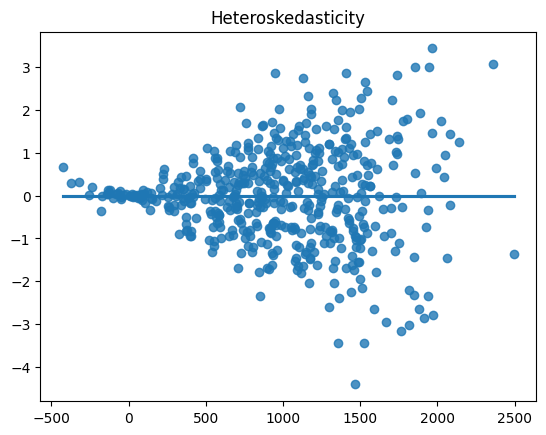

In [11]:
#Assumption 5
#graph with heteroskedasticity
import pandas as pd
import statsmodels.api as sm
import seaborn as sns

model1=sm.OLS(y,X1) #create the first model
results1=model1.fit() #fit the first model
fitted1 = results1.fittedvalues #get the fitted values
residuals1 = results1.resid #get the residuals
sns.regplot(x=fitted1,y=residuals1, #create graph
            ci=False).set(title='Heteroskedasticity')

[Text(0.5, 1.0, 'No Heteroskedasticity')]

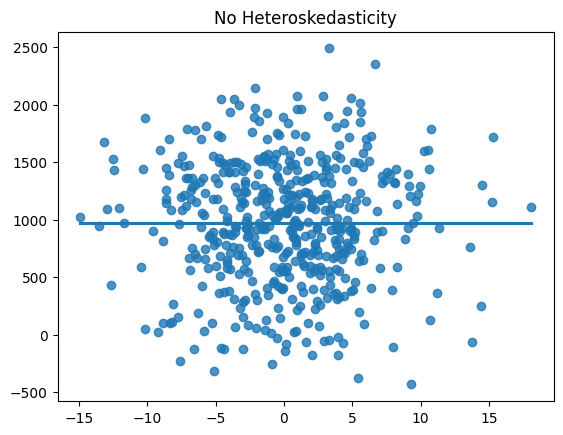

In [12]:
#Assumption 5
#Graph without heteroskedasticity
model2=sm.OLS(y,X2) #create the first model
results2=model2.fit() #fit the first model
fitted2 = results2.fittedvalues #get the fitted values
residuals2 = results2.resid #get the residuals

sns.regplot(x=residuals2,y=fitted2, #create graph
            ci=False).set(title='No Heteroskedasticity')  

In [13]:
#Assumption 5
#Breusch-Pagan test
import statsmodels.api as sm
import statsmodels.stats.api as sms
from statsmodels.compat import lzip

model1=sm.OLS(y,X1) #create the first model
results1=model1.fit() #fit the first model
fitted1 = results1.fittedvalues #get the fitted values
residuals1 = results1.resid #get the residuals

names = ['Lagrange multiplier statistic', 'p-value',
         'f-value', 'f p-value'] #attach labels to the output
test_result = sms.het_breuschpagan(results1.resid, results1.model.exog) #
lzip(names, test_result)


[('Lagrange multiplier statistic', np.float64(91.30167518503967)),
 ('p-value', np.float64(1.2335615975688903e-21)),
 ('f-value', np.float64(111.25133498586192)),
 ('f p-value', np.float64(1.3011530826804385e-23))]

In [14]:
#Assumption 5
import statsmodels.api as sm

model1=sm.OLS(y,X1) #create the first model
results1=model1.fit(cov_type='HC1') #fit the first model with robust standard errors
print(results1.summary())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       1.000
Model:                            OLS   Adj. R-squared:                  1.000
Method:                 Least Squares   F-statistic:                 9.625e+07
Date:                Tue, 13 Jan 2026   Prob (F-statistic):               0.00
Time:                        16:14:22   Log-Likelihood:                -761.25
No. Observations:                 500   AIC:                             1526.
Df Residuals:                     498   BIC:                             1535.
Df Model:                           1                                         
Covariance Type:                  HC1                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.0040      0.075     -0.054      0.9

In [15]:
#Assumption 6
#generate some data for testing the normal assumption
import numpy as np
import statsmodels.api as sm
np.random.seed(69)
y = np.random.normal(10,5,20)
X = y + np.random.normal(5,3,20)
X = sm.add_constant(X)

In [16]:
#Assumption 6
#shapiro wilk test
import statsmodels.api as sm
from scipy import stats

model=sm.OLS(y,X) #create the model
results=model.fit() #fit the model
residuals = results.resid #get the residuals

stats.shapiro(residuals) #get the test results

ShapiroResult(statistic=np.float64(0.9525869592354543), pvalue=np.float64(0.40807263542709027))